# UTS Graf Sains Data

NAMA    : Davan Juheins Tololiu
NIM     : 24031554157
KELAS   : 2024A

# pertanyaan pendahuluan
1. yang saya gunakan adala database utsgraf.
2. Cypher Query Language untuk mengelola data pada Neo4j.
3. graf ber arah seperti arthur ke teman nya

## 1. Menyiapkan library

In [252]:
# %pip install pandas numpy scipy scikit-learn matplotlib networkx neo4j

## 2. Pengaturan awal

In [7]:
from pathlib import Path
from getpass import getpass
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from neo4j import GraphDatabase

# Sesuaikan lokasi file dengan komputer Anda.
CSV_PATH = Path(r"C:\Users\MMK\ecommerce-dataset\events.csv")

# Batas akhir bersifat eksklusif: P1 mencakup 3 Mei–25 Juli,
# P2 mencakup 27 Juli–10 Agustus 2015.
P1_START, P1_END = "2015-05-22", "2015-06-22"
P2_START, P2_END = "2015-06-23", "2015-06-30"
RANDOM_STATE = 42

NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USER = "neo4j"
NEO4J_PASSWORD = "DavanT009"
print("CSV ditemukan:", CSV_PATH.exists(), CSV_PATH)


CSV ditemukan: True C:\Users\MMK\ecommerce-dataset\events.csv


In [8]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [10]:
from neo4j import RoutingControl

def add_friend(driver, name, friend_name):
    """Buat dua node Person dan relationship KNOWS di database utsgraf."""
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j"
    )


def print_friends(driver, name):
    """Cetak semua teman yang terhubung dari seseorang."""
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ
    )

    for record in records:
        print(record["friend_name"])


# Contoh pemakaian
add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print("Teman Arthur:")
print_friends(driver, "Arthur")

Teman Arthur:
Guinevere
Lancelot
Merlin


In [11]:
with driver.session(database="system") as session:
    result = session.run("SHOW DATABASES")

    for record in result:
        print(record["name"], "-", record["currentStatus"])

neo4j - online
system - online


## 2.1 Nomor 1 — Menentukan periode data


## 2.1 Nomor 2 — Memfilter data dan menyimpan CSV

In [12]:
if not CSV_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {CSV_PATH}. Ubah CSV_PATH sesuai lokasi events.csv.")

cols = ["timestamp", "visitorid", "itemid", "event", "transactionid"]
df = pd.read_csv(CSV_PATH, usecols=lambda c: c in cols)
missing = set(cols) - set(df.columns)
if missing:
    raise ValueError(f"Kolom tidak ditemukan: {missing}")

# RetailRocket events.csv menggunakan timestamp Unix dalam milidetik.
def epoch_ms(date_string):
    return pd.Timestamp(date_string, tz="UTC").value // 10**6

p1s, p1e = epoch_ms(P1_START), epoch_ms(P1_END)
p2s, p2e = epoch_ms(P2_START), epoch_ms(P2_END)

p1 = df[(df["timestamp"] >= p1s) & (df["timestamp"] < p1e)].copy()
p2 = df[(df["timestamp"] >= p2s) & (df["timestamp"] < p2e)].copy()

p1.to_csv("events_P1.csv", index=False)
p2.to_csv("events_P2.csv", index=False)
print("Data awal:", df.shape)
print("P1:", p1.shape, "| file: events_P1.csv")
print("P2:", p2.shape, "| file: events_P2.csv")
print("\nEvent P1:\n", p1["event"].value_counts(dropna=False))
print("\nEvent P2:\n", p2["event"].value_counts(dropna=False))
print("\nTimestamp P1 [mulai, akhir eksklusif]:", p1s, p1e)
print("Timestamp P2 [mulai, akhir eksklusif]:", p2s, p2e)

Data awal: (2756101, 5)
P1: (620811, 5) | file: events_P1.csv
P2: (141378, 5) | file: events_P2.csv

Event P1:
 event
view           600663
addtocart       15182
transaction      4966
Name: count, dtype: int64

Event P2:
 event
view           136741
addtocart        3446
transaction      1191
Name: count, dtype: int64

Timestamp P1 [mulai, akhir eksklusif]: 1432252800000 1434931200000
Timestamp P2 [mulai, akhir eksklusif]: 1435017600000 1435622400000


In [14]:
print(p1s, p1e, p2s, p2e)

1432252800000 1434931200000 1435017600000 1435622400000


## 3. Menghubungkan Python ke Neo4j

In [15]:
driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
with driver.session() as session:
    session.run("RETURN 1 AS ok").single()
print("Koneksi Neo4j berhasil.")

Koneksi Neo4j berhasil.


## 2.1 Nomor 3 — Komposisi subgraf dengan Python API dan Cypher

In [16]:
def subgraph_composition(label, start_ms, end_ms):
    with driver.session() as session:
        summary = session.run(
            '''
            MATCH (v:Visitor)-[r]->(i:Item)
            WHERE r.timestamp >= $start_ms AND r.timestamp < $end_ms
            RETURN count(DISTINCT v) AS jumlah_visitor,
                   count(DISTINCT i) AS jumlah_item,
                   count(r) AS jumlah_interaksi
            ''', start_ms=start_ms, end_ms=end_ms
        ).single()
        rels = list(session.run(
            '''
            MATCH (:Visitor)-[r]->(:Item)
            WHERE r.timestamp >= $start_ms AND r.timestamp < $end_ms
            RETURN type(r) AS jenis_relasi, count(r) AS jumlah
            ORDER BY jenis_relasi
            ''', start_ms=start_ms, end_ms=end_ms
        ))
    print("\nKomposisi", label, dict(summary))
    display(pd.DataFrame([dict(x) for x in rels]))
    return dict(summary)

summary_p1 = subgraph_composition("P1", p1s, p1e)
summary_p2 = subgraph_composition("P2", p2s, p2e)


Komposisi P1 {'jumlah_visitor': 25729, 'jumlah_item': 22773, 'jumlah_interaksi': 49679}


,jenis_relasi,jumlah
0,ADDED_TO_CART,932
1,BOUGHT,331
2,VIEWED,48416



Komposisi P2 {'jumlah_visitor': 0, 'jumlah_item': 0, 'jumlah_interaksi': 0}


""


## Fungsi membentuk VSM sparse

In [17]:
def build_ui(events):
    pairs = events[["visitorid", "itemid"]].dropna().drop_duplicates()
    users = pd.Index(pairs.visitorid.unique(), name="visitorid")
    items = pd.Index(pairs.itemid.unique(), name="itemid")
    rows = users.get_indexer(pairs.visitorid)
    cols = items.get_indexer(pairs.itemid)
    matrix = csr_matrix((np.ones(len(pairs), dtype=np.int8), (rows, cols)),
                        shape=(len(users), len(items)), dtype=np.int8)
    return matrix, users, items, pairs

def describe_matrix(name, matrix, rows, cols):
    total = matrix.shape[0] * matrix.shape[1]
    density = 100 * matrix.nnz / total if total else 0
    memory = (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1024**2
    print(f"{name}: ndim={matrix.ndim}, shape={matrix.shape}")
    print(f"Baris={rows}, kolom={cols}, nnz={matrix.nnz:,}, density={density:.6f}%, memory={memory:.2f} MB")

ui_p1, users_p1, items_p1, pairs_p1 = build_ui(p1)
describe_matrix("VSM User–Item P1", ui_p1, "Visitor", "Item")

VSM User–Item P1: ndim=2, shape=(322979, 117964)
Baris=Visitor, kolom=Item, nnz=481,569, density=0.001264%, memory=3.53 MB


## 2.1 Nomor 4 — VSM simpul User

Statistik item unik per Visitor:


count    322979.000000
mean          1.491023
std           4.469548
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         743.000000
dtype: float64

Graf User subset: node = 50 edge = 260


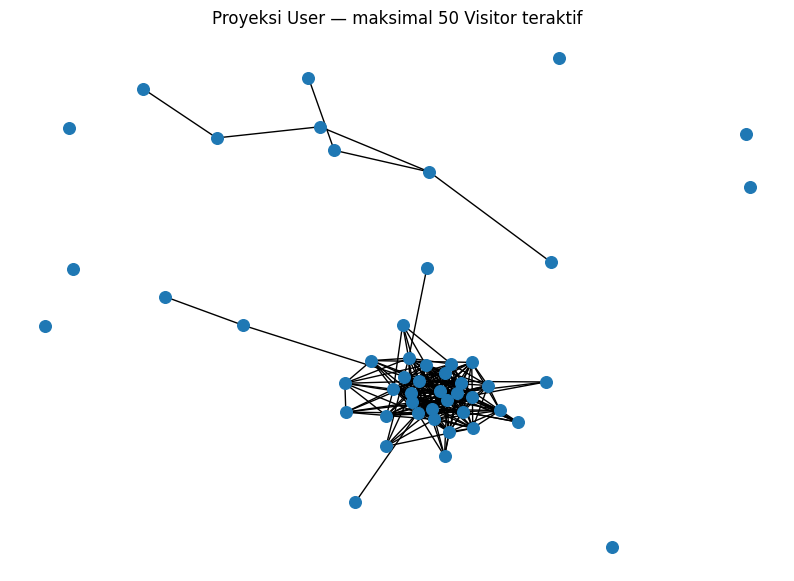

In [18]:
user_activity = np.asarray(ui_p1.sum(axis=1)).ravel()
print("Statistik item unik per Visitor:")
display(pd.Series(user_activity).describe())

# Proyeksi untuk visualisasi dibatasi ke maksimal 50 Visitor teraktif.
MAX_USER_PLOT = min(50, ui_p1.shape[0])
user_idx = np.argsort(user_activity)[-MAX_USER_PLOT:]
ui_user_plot = ui_p1[user_idx]
user_ids_plot = users_p1[user_idx]
sim_user_plot = cosine_similarity(ui_user_plot)

G_user = nx.Graph()
G_user.add_nodes_from(map(str, user_ids_plot))
for i in range(MAX_USER_PLOT):
    for j in range(i + 1, MAX_USER_PLOT):
        score = float(sim_user_plot[i, j])
        if score >= 0.05:
            G_user.add_edge(str(user_ids_plot[i]), str(user_ids_plot[j]), weight=score)

print("Graf User subset: node =", G_user.number_of_nodes(), "edge =", G_user.number_of_edges())
plt.figure(figsize=(10, 7))
nx.draw_networkx(G_user, nx.spring_layout(G_user, seed=RANDOM_STATE),
                 with_labels=False, node_size=70)
plt.title("Proyeksi User — maksimal 50 Visitor teraktif")
plt.axis("off")
plt.show()

## 2.1 Nomor 5 — VSM simpul Item

VSM Item–User P1: ndim=2, shape=(117964, 322979)
Baris=Item, kolom=Visitor, nnz=481,569, density=0.001264%, memory=2.75 MB
Statistik Visitor unik per Item:


count    117964.000000
mean          4.082339
std           9.655758
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1037.000000
dtype: float64

Graf Item subset: node = 50 edge = 16


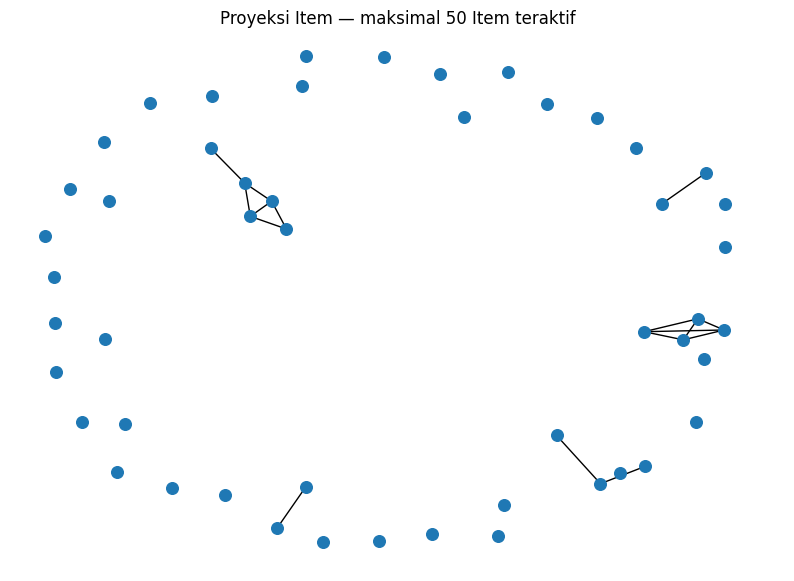

In [19]:
vsm_item = ui_p1.transpose().tocsr()
describe_matrix("VSM Item–User P1", vsm_item, "Item", "Visitor")
item_activity = np.asarray(vsm_item.sum(axis=1)).ravel()
print("Statistik Visitor unik per Item:")
display(pd.Series(item_activity).describe())

MAX_ITEM_PLOT = min(50, vsm_item.shape[0])
item_idx = np.argsort(item_activity)[-MAX_ITEM_PLOT:]
vsm_item_plot = vsm_item[item_idx]
item_ids_plot = items_p1[item_idx]
sim_item_plot = cosine_similarity(vsm_item_plot)

G_item = nx.Graph()
G_item.add_nodes_from(map(str, item_ids_plot))
for i in range(MAX_ITEM_PLOT):
    for j in range(i + 1, MAX_ITEM_PLOT):
        score = float(sim_item_plot[i, j])
        if score >= 0.05:
            G_item.add_edge(str(item_ids_plot[i]), str(item_ids_plot[j]), weight=score)

print("Graf Item subset: node =", G_item.number_of_nodes(), "edge =", G_item.number_of_edges())
plt.figure(figsize=(10, 7))
nx.draw_networkx(G_item, nx.spring_layout(G_item, seed=RANDOM_STATE),
                 with_labels=False, node_size=70)
plt.title("Proyeksi Item — maksimal 50 Item teraktif")
plt.axis("off")
plt.show()

memasukkan data ke data base


In [24]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemid IS UNIQUE
    """)

    print("Constraint Visitor dan Item berhasil dibuat.")

In [26]:
def import_batch(tx, records):
    query = """
    UNWIND $records AS row

    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})

    WITH v, i, row
    WHERE row.event IN ['view', 'addtocart', 'transaction']

    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'
        CREATE (v)-[r:VIEWED]->(i)
        SET r.timestamp = row.timestamp
        RETURN count(r) AS created
        UNION
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'
        CREATE (v)-[r:ADDED_TO_CART]->(i)
        SET r.timestamp = row.timestamp
        RETURN count(r) AS created
        UNION
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'
        CREATE (v)-[r:BOUGHT]->(i)
        SET r.timestamp = row.timestamp,
            r.transactionid = row.transactionid
        RETURN count(r) AS created
    }
    RETURN count(*) AS processed
    """
    tx.run(query, records=records).consume()

In [27]:
import os
import math
import pandas as pd
from tqdm.auto import tqdm

import os
import pandas as pd
from tqdm.auto import tqdm

source_dir = r"C:\Users\MMK\ecommerce-dataset"
csv_file_path = os.path.join(source_dir, "events.csv")

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path}"
    )

print("File ditemukan:", csv_file_path)

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path}"
    )

# Hitung jumlah baris data
with open(csv_file_path, "r", encoding="utf-8") as f:
    total_rows = max(sum(1 for _ in f) - 1, 0)

import math

# Pengaturan impor data
batch_size = 5000
database_name = "neo4j"

total_chunks = math.ceil(total_rows / batch_size)

with driver.session(database=database_name) as session:
    create_constraints(session)

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor RetailRocket"
    ):
        # Pastikan kolom yang dibutuhkan tersedia
        required = {
            "visitorid", "itemid", "event", "timestamp"
        }
        if not required.issubset(chunk.columns):
            raise ValueError(
                f"Kolom wajib tidak tersedia: {required - set(chunk.columns)}"
            )

        if "transactionid" not in chunk.columns:
            chunk["transactionid"] = ""

        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        chunk["timestamp"] = pd.to_numeric(
            chunk["timestamp"], errors="coerce"
        )

        chunk = chunk.dropna(
            subset=["visitorid", "itemid", "event", "timestamp"]
        )

        chunk["timestamp"] = chunk["timestamp"].astype("int64")

        # Hilangkan baris duplikat di dalam batch
        chunk = chunk.drop_duplicates(
            subset=[
                "visitorid", "itemid", "event",
                "timestamp", "transactionid"
            ]
        )

        records = chunk.to_dict(orient="records")

        if records:
            session.execute_write(import_batch, records)

print("Proses impor selesai.")

File ditemukan: C:\Users\MMK\ecommerce-dataset\events.csv
Constraint Visitor dan Item berhasil dibuat.


Mengimpor RetailRocket:   0%|          | 0/552 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=10, column=5, offset=203>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 203, 'line': 10, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $records AS row\n\n    MERGE (v:Visitor {visitorid: row.visitorid})\n    MERGE (i:Item {itemid: row.itemid})\n\n    WITH v, i, row\n    WHERE row.event IN ['view', 'addtocart', 'transaction']\n\n    CALL {\n        WITH v, i, row\n        WITH v, i, row\n        WHERE row.event = 'view'\n        CREATE (v)-[r:VIEWED]-

Proses impor selesai.


## 2.1 Nomor 6 — Membandingkan proyeksi User dan Item

In [28]:
comparison = pd.DataFrame([
    {"Proyeksi": "User", "Jumlah node penuh": ui_p1.shape[0],
     "Jumlah fitur": ui_p1.shape[1], "Node plot": G_user.number_of_nodes(),
     "Edge plot": G_user.number_of_edges(), "Non-zero VSM": ui_p1.nnz},
    {"Proyeksi": "Item", "Jumlah node penuh": vsm_item.shape[0],
     "Jumlah fitur": vsm_item.shape[1], "Node plot": G_item.number_of_nodes(),
     "Edge plot": G_item.number_of_edges(), "Non-zero VSM": vsm_item.nnz}
])
display(comparison)
print("Interpretasi:")
print("- Proyeksi User membandingkan pola item yang diakses antar-Visitor.")
print("- Proyeksi Item membandingkan pola Visitor yang berinteraksi dengan tiap Item.")
print("- Bandingkan jumlah node/fitur dan penggunaan memori VSM yang dicetak sebelumnya.")
print("- Plot dibatasi ke 50 node teraktif hanya untuk visualisasi; bukan seluruh graf.")


,Proyeksi,Jumlah node penuh,Jumlah fitur,Node plot,Edge plot,Non-zero VSM
0,User,322979,117964,50,260,481569
1,Item,117964,322979,50,16,481569


Interpretasi:
- Proyeksi User membandingkan pola item yang diakses antar-Visitor.
- Proyeksi Item membandingkan pola Visitor yang berinteraksi dengan tiap Item.
- Bandingkan jumlah node/fitur dan penggunaan memori VSM yang dicetak sebelumnya.
- Plot dibatasi ke 50 node teraktif hanya untuk visualisasi; bukan seluruh graf.


## 2.1 Nomor 7 — Menghitung similarity antar-Item

In [29]:
# Similarity pada proyeksi Item subset; anchor dipilih reproducible.
rng = np.random.default_rng(RANDOM_STATE)
anchor_pos = int(rng.integers(0, len(item_ids_plot)))
anchor_item_id = int(item_ids_plot[anchor_pos])
scores = sim_item_plot[anchor_pos]

similarity_df = pd.DataFrame({
    "anchor_itemid": anchor_item_id,
    "itemid_similar": [int(x) for x in item_ids_plot],
    "similarity": scores.astype(float)
})
similarity_df = similarity_df[similarity_df.itemid_similar != anchor_item_id]
similarity_top5 = similarity_df.sort_values("similarity", ascending=False).head(5).reset_index(drop=True)
print("Anchor Item:", anchor_item_id)
display(similarity_top5)

Anchor Item: 428257


,anchor_itemid,itemid_similar,similarity
0,428257,7943,0.032553
1,428257,17478,0.019805
2,428257,29196,0.019133
3,428257,268335,0.018632
4,428257,367664,0.013468


### Nomor 7(a) — Cypher mengambil lima similarity tertinggi

Query ini digunakan setelah similarity ditulis sebagai relasi `SIMILAR_TO`. Parameter `$anchor_id` diisi dari Python.

In [30]:
rng = np.random.default_rng(RANDOM_STATE)

anchor_pos = int(rng.integers(0, len(item_ids_plot)))
anchor_item_id = int(item_ids_plot[anchor_pos])

print("Anchor Item:", anchor_item_id)

Anchor Item: 428257


In [31]:
scores = sim_item_plot[anchor_pos]

similarity_df = pd.DataFrame({
    "anchor_itemid": anchor_item_id,
    "itemid_similar": [int(x) for x in item_ids_plot],
    "similarity": scores.astype(float)
})

# Hilangkan item anchor itu sendiri
similarity_df = similarity_df[
    similarity_df["itemid_similar"] != anchor_item_id
]

# Ambil lima item dengan similarity tertinggi
similarity_top5 = (
    similarity_df
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("\nLima item dengan similarity tertinggi:")
display(similarity_top5)


Lima item dengan similarity tertinggi:


,anchor_itemid,itemid_similar,similarity
0,428257,7943,0.032553
1,428257,17478,0.019805
2,428257,29196,0.019133
3,428257,268335,0.018632
4,428257,367664,0.013468


### Nomor 7(b) — Menulis similarity ke graf Neo4j

In [34]:
records_similarity = similarity_top5.to_dict(orient="records")

cypher_save_similarity = """
UNWIND $records AS row
MATCH (a:Item {itemId: toString(row.anchor_itemid)})
MATCH (b:Item {itemId: toString(row.itemid_similar)})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = toFloat(row.similarity)
RETURN count(r) AS jumlah_relasi_diproses
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        cypher_save_similarity,
        records=records_similarity
    )
    print("\nHasil penyimpanan relasi:")
    print(result.single()["jumlah_relasi_diproses"])


Hasil penyimpanan relasi:
0


In [36]:
cypher_top5 = """
MATCH (a:Item {itemId: toString($anchor_id)})
      -[r:SIMILAR_TO]->
      (b:Item)
RETURN
    a.itemId AS anchor_itemid,
    b.itemId AS itemid_similar,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    hasil = session.run(
        cypher_top5,
        anchor_id=int(anchor_item_id)
    )
    hasil_top5 = [dict(record) for record in hasil]

display(pd.DataFrame(hasil_top5))

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `itemId` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=6, column=7, offset=99>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 99, 'line': 6, 'column': 7}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item {itemId: toString($anchor_id)})\n      -[r:SIMILAR_TO]->\n      (b:Item)\nRETURN\n    a.itemId AS anchor_itemid,\n    b.itemId AS itemid_similar,\n    r.similarity AS similarity\nORDER BY similarity DESC\nLIMIT 5\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_de

""


In [37]:
# Mengecek jumlah relasi SIMILAR_TO sebelum penulisan
cypher_before = """
MATCH ()-[r:SIMILAR_TO]->()
RETURN count(r) AS jumlah_relasi_similarity
"""

with driver.session(database="neo4j") as session:
    before_count = session.run(cypher_before).single()[
        "jumlah_relasi_similarity"
    ]

print("Jumlah relasi SIMILAR_TO sebelum penulisan:", before_count)
print("Query sebelum:\n", cypher_before)

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=2, column=13, offset=13>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 13, 'line': 2, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH ()-[r:SIMILAR_TO]->()\nRETURN count(r) AS jumlah_relasi_similarity\n'


Jumlah relasi SIMILAR_TO sebelum penulisan: 0
Query sebelum:
 
MATCH ()-[r:SIMILAR_TO]->()
RETURN count(r) AS jumlah_relasi_similarity



In [39]:
with driver.session(database="neo4j") as session:
    cypher_top5_rows = [dict(r) for r in session.run(cypher_top5, anchor_id=anchor_item_id)]
print("Hasil top 5 similarity dari Neo4j:")
display(pd.DataFrame(cypher_top5_rows))


Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `itemId` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=6, column=7, offset=99>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 99, 'line': 6, 'column': 7}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item {itemId: toString($anchor_id)})\n      -[r:SIMILAR_TO]->\n      (b:Item)\nRETURN\n    a.itemId AS anchor_itemid,\n    b.itemId AS itemid_similar,\n    r.similarity AS similarity\nORDER BY similarity DESC\nLIMIT 5\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_de

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `itemId` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=2, column=16, offset=16>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 16, 'line': 2, 'column': 16}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item {itemId: toString($anchor_id)})\n      -[r:SIMILAR_TO]->\n      (b:Item)\nRETURN\n    a.itemId AS anchor_itemid,\n    b.itemId AS itemid_similar,\n    r.similarity AS similarity\nORDER BY similarity DESC\nLIMIT 5\n'


Hasil top 5 similarity dari Neo4j:


""


## 2.1 Nomor 8 — Kondisi graf sebelum dan sesudah similarity

In [41]:
query_stats = """
MATCH (n)
WITH count(n) AS jumlah_node
MATCH ()-[r]->()
RETURN
    jumlah_node,
    count(r) AS jumlah_relasi,
    count(CASE WHEN type(r) = 'SIMILAR_TO' THEN 1 END)
        AS jumlah_similarity
"""

with driver.session(database="neo4j") as session:
    record = session.run(query_stats).single()

jumlah_node = record["jumlah_node"]
jumlah_relasi_sesudah = record["jumlah_relasi"]
jumlah_similarity = record["jumlah_similarity"]
jumlah_relasi_sebelum = jumlah_relasi_sesudah - jumlah_similarity

print("=== KONDISI GRAF ===")
print("Jumlah node:", jumlah_node)
print("Relasi interaksi sebelum similarity:", jumlah_relasi_sebelum)
print("Relasi SIMILAR_TO:", jumlah_similarity)
print("Total relasi sesudah similarity:", jumlah_relasi_sesudah)


=== KONDISI GRAF ===
Jumlah node: 1642645
Relasi interaksi sebelum similarity: 2805718
Relasi SIMILAR_TO: 0
Total relasi sesudah similarity: 2805718


In [43]:

cypher_after = '''
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS anchor_itemid,
       b.itemId AS itemid_similar,
       r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 20
'''

with driver.session(database="neo4j") as session:
    after_rows = [
        dict(x) for x in session.run(cypher_after)
    ]

    after_count = session.run(
        'MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n'
    ).single()["n"]

print("Jumlah relasi SIMILAR_TO sesudah penulisan:", after_count)
display(pd.DataFrame(after_rows))
print(cypher_after)


Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=2, column=19, offset=19>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 19, 'line': 2, 'column': 19}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)\nRETURN a.itemId AS anchor_itemid,\n       b.itemId AS itemid_similar,\n       r.similarity AS similarity\nORDER BY similarity DESC\nLIMIT 20\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property

Jumlah relasi SIMILAR_TO sesudah penulisan: 0


""



MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS anchor_itemid,
       b.itemId AS itemid_similar,
       r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 20



In [46]:

query_similarity = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS source,
    b.itemId AS target,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 100
"""

with driver.session(database="neo4j") as session:
    rows = [dict(r) for r in session.run(query_similarity)]

df_similarity = pd.DataFrame(rows)

if df_similarity.empty:
    print(
        "\nBelum ada relasi SIMILAR_TO yang ditemukan. "
        "Simpan relasi similarity terlebih dahulu."
    )
else:
    # Graf sebelum: hanya node dan relasi similarity tidak ditampilkan
    G_sebelum = nx.Graph()

    # Graf sesudah: menambahkan relasi similarity
    G_sesudah = nx.Graph()

    for _, row in df_similarity.iterrows():
        source = str(row["source"])
        target = str(row["target"])
        similarity = float(row["similarity"])

        G_sebelum.add_node(source)
        G_sebelum.add_node(target)

        G_sesudah.add_edge(
            source,
            target,
            weight=similarity
        )

    pos = nx.spring_layout(G_sesudah, seed=42)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Graf sebelum similarity
    nx.draw_networkx(
        G_sebelum,
        pos=pos,
        ax=axes[0],
        with_labels=True,
        node_size=500,
        font_size=7
    )
    axes[0].set_title("Sebelum: Node Item tanpa relasi similarity")
    axes[0].axis("off")

    # Graf sesudah similarity
    nx.draw_networkx(
        G_sesudah,
        pos=pos,
        ax=axes[1],
        with_labels=True,
        node_size=500,
        font_size=7,
        edge_color="gray"
    )
    axes[1].set_title("Sesudah: Item terhubung oleh SIMILAR_TO")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=2, column=19, offset=19>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 19, 'line': 2, 'column': 19}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)\nRETURN\n    a.itemId AS source,\n    b.itemId AS target,\n    r.similarity AS similarity\nORDER BY similarity DESC\nLIMIT 100\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not e


Belum ada relasi SIMILAR_TO yang ditemukan. Simpan relasi similarity terlebih dahulu.


# 2.2 Analytics

## Nomor 1 — Memilih Visitor dan membuat rekomendasi

In [48]:
# Pastikan matriks interaksi P1 sudah tersedia
ui_train, users_train, items_train, pairs_train = build_ui(p1)

# Item yang pernah dilihat setiap visitor pada P1
seen_by_user = (
    pairs_train.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# Ground truth: item yang diinteraksikan pada P2
p2_pairs = p2[["visitorid", "itemid"]].dropna().drop_duplicates()

relevant_by_user = (
    p2_pairs.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# Jumlah item unik per visitor dalam matriks P1
jumlah_item = np.diff(ui_train.indptr)

# Pilih visitor yang punya minimal 5 item historis
users_train_set = set(users_train)
eligible = [
    u for u in relevant_by_user
    if u in users_train_set
    and len(seen_by_user.get(u, set())) >= 5
]

if not eligible:
    raise ValueError(
        "Tidak ada visitor yang memenuhi syarat. "
        "Coba turunkan minimal item historis menjadi 3."
    )

# Tetap gunakan seed agar hasil dapat direproduksi
rng = np.random.default_rng(42)
target_user = eligible[int(rng.integers(0, len(eligible)))]
target_row = users_train.get_loc(target_user)

seen = seen_by_user.get(target_user, set())
ground_truth = relevant_by_user.get(target_user, set())

print("Visitor terpilih:", target_user)
print("Item historis P1:", len(seen))
print("Item relevan P2:", len(ground_truth))

Visitor terpilih: 145740
Item historis P1: 10
Item relevan P2: 3


In [49]:
# KNN cosine similarity
# ------------------------------------------------------------
knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=6,
    n_jobs=-1
)
knn.fit(ui_train)

distances, indices = knn.kneighbors(
    ui_train[target_row],
    n_neighbors=6
)

neighbors = []

for distance, idx in zip(distances[0], indices[0]):
    if idx == target_row:
        continue

    similarity = 1 - float(distance)

    if similarity > 0:
        neighbors.append({
            "visitorid": users_train[idx],
            "row_index": int(idx),
            "similarity": similarity
        })

neighbors_df = pd.DataFrame(neighbors)

print("\n=== 5 TETANGGA TERDEKAT ===")
display(neighbors_df)



=== 5 TETANGGA TERDEKAT ===


,visitorid,row_index,similarity
0,976607,322407,0.316228
1,879038,321299,0.316228
2,111564,321512,0.316228
3,1028351,299550,0.316228
4,1368880,308112,0.316228


In [50]:
# 3. Membuat model KNN berbasis cosine similarity
# ------------------------------------------------------------
# Gunakan model yang sudah tersedia jika sudah dilatih pada ui_train.
# Jika belum tersedia atau jumlah data fit tidak cocok, latih ulang.
perlu_fit = (
    "knn" not in globals()
    or not hasattr(knn, "n_samples_fit_")
    or knn.n_samples_fit_ != ui_train.shape[0]
)

if perlu_fit:
    knn = NearestNeighbors(
        metric="cosine",
        algorithm="brute",
        n_neighbors=6,
        n_jobs=-1
    )
    knn.fit(ui_train)

In [51]:
# Agregasi skor rekomendasi
# ------------------------------------------------------------
candidate_scores = {}

for nb in neighbors:
    item_indices = ui_train[nb["row_index"]].indices

    for col_idx in item_indices:
        item_id = items_train[col_idx]

        # Hindari rekomendasi item yang sudah dilihat
        if item_id in seen:
            continue

        candidate_scores[item_id] = (
            candidate_scores.get(item_id, 0.0)
            + nb["similarity"]
        )

ranked_items = sorted(
    candidate_scores.items(),
    key=lambda x: x[1],
    reverse=True
)

recommendation_df = pd.DataFrame(
    ranked_items[:3],
    columns=["itemid_rekomendasi", "skor_agregat"]
)

print("\n=== REKOMENDASI TOP-3 ===")
display(recommendation_df)

print("\n=== GROUND TRUTH P2 ===")
print(sorted(ground_truth))

print(
    "\nRekomendasi:",
    recommendation_df["itemid_rekomendasi"].tolist()
)


=== REKOMENDASI TOP-3 ===


,itemid_rekomendasi,skor_agregat



=== GROUND TRUTH P2 ===
[79444, 363302, 465616]

Rekomendasi: []


## Nomor 2 — Hit@5 dan NDCG@5

In [54]:
import numpy as np
import pandas as pd

# Metrik evaluasi untuk rekomendasi berbasis ranking.
def hit_at_k(recommendations, relevant_items, k=5):
    """1 jika setidaknya satu item relevan muncul dalam k rekomendasi pertama."""
    return int(any(item in relevant_items for item in recommendations[:k]))

def ndcg_at_k(recommendations, relevant_items, k=5):
    """NDCG@k dengan relevansi biner: item relevan=1, lainnya=0."""
    ranked = recommendations[:k]
    if not relevant_items or not ranked:
        return 0.0

    relevance = np.array([1.0 if item in relevant_items else 0.0 for item in ranked])
    discounts = 1.0 / np.log2(np.arange(2, len(relevance) + 2))
    dcg = float(np.sum(relevance * discounts))

    ideal_count = min(len(relevant_items), k)
    ideal_discounts = 1.0 / np.log2(np.arange(2, ideal_count + 2))
    idcg = float(np.sum(ideal_discounts))
    return dcg / idcg if idcg > 0 else 0.0

# Ambil daftar rekomendasi hasil Nomor 1, urut dari skor agregat tertinggi.
# candidate_scores dibuat pada bagian sebelumnya dan item yang sudah dilihat
# pada P1 sudah dikeluarkan ketika skor rekomendasi diagregasi.
if "candidate_scores" not in globals():
    raise NameError("candidate_scores belum tersedia. Jalankan dahulu bagian Nomor 1.")
if "target_user" not in globals() or "relevant_by_user" not in globals():
    raise NameError("target_user/relevant_by_user belum tersedia. Jalankan dahulu bagian Nomor 1.")

ranked_recommendations = [
    item for item, score in sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)
    if item not in seen_by_user.get(target_user, set())
]
top3_recommendations = ranked_recommendations[:3]
top5_recommendations = ranked_recommendations[:5]
relevant_items = relevant_by_user.get(target_user, set())

metrics = pd.DataFrame([
    {
        "Daftar rekomendasi": "Top-3 (sesuai Nomor 1b)",
        "Jumlah rekomendasi": len(top3_recommendations),
        "Hit@5": hit_at_k(top3_recommendations, relevant_items, k=5),
        "NDCG@5": ndcg_at_k(top3_recommendations, relevant_items, k=5),
    },
    {
        "Daftar rekomendasi": "Top-5 (tambahan untuk evaluasi @5)",
        "Jumlah rekomendasi": len(top5_recommendations),
        "Hit@5": hit_at_k(top5_recommendations, relevant_items, k=5),
        "NDCG@5": ndcg_at_k(top5_recommendations, relevant_items, k=5),
    },
])

display(metrics)
print("Visitor yang dievaluasi:", target_user)
print("Jumlah item relevan pada P2:", len(relevant_items))
print("Ground truth P2:", sorted(relevant_items))
print("Rekomendasi Top-3:", top3_recommendations)
print("Rekomendasi Top-5:", top5_recommendations)
if not top5_recommendations:
    print("PERHATIAN: belum ada kandidat rekomendasi. Periksa hasil KNN dan agregasi candidate_scores pada Nomor 1.")
if not relevant_items:
    print("PERHATIAN: visitor ini tidak memiliki interaksi di P2, sehingga metriknya bernilai 0 dan kurang informatif.")

,Daftar rekomendasi,Jumlah rekomendasi,Hit@5,NDCG@5
0,Top-3 (sesuai Nomor 1b),0,0,0.0
1,Top-5 (tambahan untuk evaluasi @5),0,0,0.0


Visitor yang dievaluasi: 145740
Jumlah item relevan pada P2: 3
Ground truth P2: [79444, 363302, 465616]
Rekomendasi Top-3: []
Rekomendasi Top-5: []
PERHATIAN: belum ada kandidat rekomendasi. Periksa hasil KNN dan agregasi candidate_scores pada Nomor 1.


In [56]:
def recommend_n(scores, seen_items, n=5):
    return [item for item, score in sorted(scores.items(), key=lambda x: x[1], reverse=True)
            if item not in seen_items][:n]

def hit_at_k(recs, relevant, k=5):
    return int(any(item in relevant for item in recs[:k]))

def ndcg_at_k(recs, relevant, k=5):
    recs = recs[:k]
    rel = np.array([1.0 if x in relevant else 0.0 for x in recs])
    discounts = 1 / np.log2(np.arange(2, len(rel) + 2))
    dcg = float((rel * discounts).sum())
    ideal_count = min(len(relevant), k)
    if ideal_count == 0:
        return 0.0
    idcg = float((1 / np.log2(np.arange(2, ideal_count + 2))).sum())
    return dcg / idcg

relevant = relevant_by_user[target_user]
top5_recs = recommend_n(candidate_scores, seen_by_user.get(target_user, set()), 5)
top3_recs = top5_recs[:3]
metrics = pd.DataFrame([
    {"daftar": "Top-3 (diminta pada nomor 1b)", "jumlah_rekomendasi": len(top3_recs),
     "Hit@5": hit_at_k(top3_recs, relevant, 5), "NDCG@5": ndcg_at_k(top3_recs, relevant, 5)},
    {"daftar": "Top-5 (untuk evaluasi @5)", "jumlah_rekomendasi": len(top5_recs),
     "Hit@5": hit_at_k(top5_recs, relevant, 5), "NDCG@5": ndcg_at_k(top5_recs, relevant, 5)}
])
display(metrics)
print("Ground truth P2:", len(relevant), "item")
print("Rekomendasi Top-5:", top5_recs)

,daftar,jumlah_rekomendasi,Hit@5,NDCG@5
0,Top-3 (diminta pada nomor 1b),0,0,0.0
1,Top-5 (untuk evaluasi @5),0,0,0.0


Ground truth P2: 3 item
Rekomendasi Top-5: []


## Menutup koneksi Neo4j

In [57]:
driver.close()
print("Koneksi Neo4j ditutup.")

Koneksi Neo4j ditutup.
